
PCA降维的过程

1）将原始数据做转置运算，每一行代表一个维度

2）每一行（代表一个属性字段）进行零均值化，即减去这一行的均值

3）得到原始数据的协方差矩阵

4）求出协方差矩阵的特征值及对应的特征向量的单位向量

5）将特征向量按对应特征值大小从上到下按行排列成矩阵，取前k行组成矩阵P

6）用上面得到矩阵P和标准化后数据相乘，即可得到降维到k维后的数据



1.pca实现鸢尾花数据降维

均值向量为：[5.84333333 3.05733333 3.758      1.19933333] 

协方差矩阵:
[[ 0.68569351 -0.042434    1.27431544  0.51627069]
 [-0.042434    0.18997942 -0.32965638 -0.12163937]
 [ 1.27431544 -0.32965638  3.11627785  1.2956094 ]
 [ 0.51627069 -0.12163937  1.2956094   0.58100626]]
特征值为：[4.22824171 0.24267075 0.0782095  0.02383509]
特征向量为：
[[ 0.36138659 -0.65658877 -0.58202985  0.31548719]
 [-0.08452251 -0.73016143  0.59791083 -0.3197231 ]
 [ 0.85667061  0.17337266  0.07623608 -0.47983899]
 [ 0.3582892   0.07548102  0.54583143  0.75365743]]
最终需要的特征向量：
[[ 0.36138659 -0.65658877 -0.58202985  0.31548719]
 [-0.08452251 -0.73016143  0.59791083 -0.3197231 ]
 [ 0.85667061  0.17337266  0.07623608 -0.47983899]
 [ 0.3582892   0.07548102  0.54583143  0.75365743]]
最终重构结果为:
[[5.08303897 3.51741393 1.40321372 0.21353169]
 [4.7462619  3.15749994 1.46356177 0.24024592]
 [4.70411871 3.1956816  1.30821697 0.17518015]
 [4.6422117  3.05696697 1.46132981 0.23973218]
 [5.07175511 3.52655486 1.36373845 0.19699991]
 [5.5058104

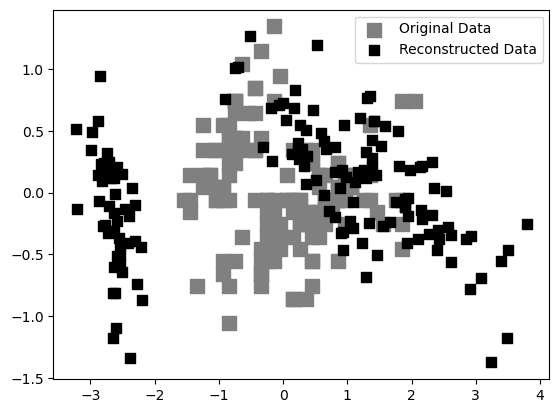

In [11]:
from sklearn import datasets
import numpy as np
import matplotlib.pyplot as plt

class PCAtest():
    def __init__(self, k):
        # 降到k维
        self.k = k


    # 加载鸢尾花数据集中的特征作为PCA的原始数据集
    def loadIris(self):
        data = datasets.load_iris()["data"]
        return data


    # 数据标准化（去均值）
    def stand_data(self, data):
        # axis = 0,按列取值求均值
        mean_vector = np.mean(data, axis=0)
        return mean_vector, data - mean_vector


    # 计算协方差矩阵
    # 协方差计算的是不同维度之间的协方差，不是不同样本的,要确定我们数据维度是按行还是列
    def getCovMat(self, standData):
        # rowvar=0表示数据的每一列代表一个维度
        return np.cov(standData, rowvar=0)


    # 计算协方差矩阵的特征值和特征向量
    # linalg.eig()可以用来计算计算特征值和对应的特征向量
    # 输入参数是一个方阵，得到两个值：w，v。
    # w：特征值。每个特征值根据它的多重性重复。这个数组将是复杂类型，除非虚数部分为0。当传进的参数a是实数时，得到的特征值是实数
    # v：特征向量。每个特征值对应的特征向量，相同特征值可能对应的特征向量不同
    def getFValueAndFVector(self, covMat):
        fValue, fVector = np.linalg.eig(covMat)
        return fValue, fVector

    # 得到特征向量矩阵
    def getVectorMatrix(self, fValue, fVector):
        # 从大到小排序，并返回排序后的原索引值
        fValueSort = np.argsort(-fValue)
        fValueTopN = fValueSort[:self.k] # 取最大的k个特征值对应的特征向量
        return fVector[:, fValueTopN]

    # 得到降维后的数据
    def getResult(self, data, vectorMat):
        return np.dot(data, vectorMat)   # 前k个较大特征值对应的特征向量和标准化后数据做内积运算，便可得到降维后的数据

def show_picture(dataMat, reconMat): # 可视化原始数据和降维数据
    fig = plt.figure()
    ax = fig.add_subplot(111)
    ax.scatter(dataMat[:, 0].flatten(), dataMat[:, 1].flatten(), marker='s', s=90, c='gray', label='Original Data')
    ax.scatter(reconMat[:, 0].flatten(), reconMat[:, 1].flatten(), marker='s', s=50, c='black', label='Reconstructed Data')
    plt.legend()
    plt.show()

if __name__ == "__main__":
    pca = PCAtest(2)
    data = pca.loadIris()

    (mean_vector, standdata) = pca.stand_data(data)
    print("均值向量为：%s \n" % mean_vector)
    cov_mat = pca.getCovMat(standdata)
    print("协方差矩阵:\n%s" % cov_mat)
    fvalue, fvector = pca.getFValueAndFVector(cov_mat)
    print("特征值为：%s\n特征向量为：\n%s" % (fvalue, fvector))
    fvectormat = pca.getVectorMatrix(fvalue, fvector)
    print("最终需要的特征向量：\n%s" % fvector)
    newdata = pca.getResult(standdata, fvectormat)
 
    print("最终重构结果为:\n{}".format(np.mat(newdata) * fvectormat.T + mean_vector))

    # 可视化原始数据和降维后的数据
    show_picture(standdata, newdata)


2.pca实现图像降维

In [1]:
import numpy as np
import cv2 as cv
 
#数据中心化
def Z_centered(dataMat):
	rows,cols=dataMat.shape
	meanVal = np.mean(dataMat, axis=0)  # 按列求均值，即求各个特征的均值
	meanVal = np.tile(meanVal,(rows,1))
	newdata = dataMat-meanVal
	return newdata, meanVal
 
	
#最小化降维造成的损失，确定k
def Percentage2n(eigVals, percentage):
	sortArray = np.sort(eigVals)  # 升序
	sortArray = sortArray[-1::-1]  # 逆转，即降序
	arraySum = sum(sortArray)
	tmpSum = 0
	num = 0
	for i in sortArray:
		tmpSum += i
		num += 1
		if tmpSum >= arraySum * percentage:
			return num
	
#得到最大的k个特征值和特征向量
def EigDV(covMat, p):
	D, V = np.linalg.eig(covMat) # 得到特征值和特征向量
	k = Percentage2n(D, p) # 确定k值
	print("保留99%信息，降维后的特征个数："+str(k)+"\n")
	eigenvalue = np.argsort(D)
	K_eigenValue = eigenvalue[-1:-(k+1):-1]
	K_eigenVector = V[:,K_eigenValue]
	return K_eigenValue, K_eigenVector
	
#得到降维后的数据
def getlowDataMat(DataMat, K_eigenVector):
	return DataMat * K_eigenVector
 
#重构数据
def Reconstruction(lowDataMat, K_eigenVector, meanVal):
	reconDataMat = lowDataMat * K_eigenVector.T + meanVal
	return reconDataMat
 
#PCA算法
def PCA(data, p):
	dataMat = np.float32(np.mat(data))
	# 数据中心化
	dataMat, meanVal = Z_centered(dataMat)

    # 计算协方差矩阵
	covMat = np.cov(dataMat, rowvar=0)

	#得到最大的k个特征值和特征向量
	D, V = EigDV(covMat, p)

	#得到降维后的数据
	lowDataMat = getlowDataMat(dataMat, V)

	#重构数据
	reconDataMat = Reconstruction(lowDataMat, V, meanVal)
	
	return reconDataMat
 
if __name__=='__main__':
	imagePath = r'banana.jpg'
	image = cv.imread(imagePath)
	image=cv.cvtColor(image,cv.COLOR_BGR2GRAY)
	rows,cols=image.shape
	print("降维前的特征个数："+str(cols)+"\n")
	print(image)
	print('----------------------------------------')
	reconImage = PCA(image, 0.99)
	reconImage = reconImage.astype(np.uint8)
	print(reconImage)
	cv.imshow('test',reconImage)
	cv.waitKey(0)
	cv.destroyAllWindows()


降维前的特征个数：500

[[255 255 255 ... 255 255 255]
 [255 255 255 ... 255 255 255]
 [255 255 255 ... 255 255 255]
 ...
 [255 255 255 ... 255 255 255]
 [255 255 255 ... 255 255 255]
 [255 255 255 ... 255 255 255]]
----------------------------------------
保留99%信息，降维后的特征个数：34

[[255 255 255 ... 255 255 255]
 [255 255 255 ... 255 255 255]
 [255 255 255 ... 255 255 255]
 ...
 [255 255 255 ... 255 255 255]
 [255 255 255 ... 255 255 255]
 [255 255 255 ... 255 255 255]]


C:\Users\liang\AppData\Local\Temp\ipykernel_31468\3462297580.py:74: ComplexWarning: Casting complex values to real discards the imaginary part
  reconImage = reconImage.astype(np.uint8)
